# Étendue and the brightness theorem: phase space, lenses that cheat and the temperature of a burning glass

Imaging optics cares about where a ray goes; illumination optics cares about
how much light arrives and how evenly. Both are governed by one invariant,
the **étendue**: the volume that a beam occupies in phase space. A ray
crossing a plane $z = \text{const}$ at $(x, y)$ with the unit direction
$(L, M, N)$ in a medium of index $n$ has the canonical coordinates

$$(x,\ y,\ p,\ q) = (x,\ y,\ nL,\ nM),$$

position and optical direction cosine, the transverse wave vector over
$k_0$. The étendue of a beam is

$$G = \int dx\,dy\,dp\,dq = n^2 \int \cos\theta\,dA\,d\Omega,$$

and for a Lambertian source of area $A$ that emits into the numerical
aperture $\mathrm{NA} = n\sin\theta$ it is $G = \pi A\,\mathrm{NA}^2$. In a
2D (meridional) world, a strip of width $w$ into $\pm\mathrm{NA}$ has
$G = 2w\,\mathrm{NA}$.

Rays obey Hamilton's equations with $p, q$ as the momenta of $x, y$ and
$-\sqrt{n^2 - p^2 - q^2}$ as the Hamiltonian, so every lossless optical system,
however aberrated, maps phase space **symplectically**: its Jacobian
$J = \partial(x', y', p', q')/\partial(x, y, p, q)$ obeys
$J^T\Omega J = \Omega$ and has $\det J = 1$ (Liouville's theorem). Three
consequences run through all of illumination optics:

1. **Étendue cannot shrink.** Lenses, mirrors, light pipes and prisms only
   reshape the occupied volume. Apertures cut it (and the power with it),
   diffusers and mixing enlarge it.
2. **Brightness theorem.** The basic radiance $L/n^2$, power per phase space
   volume, is carried unchanged along every ray. An image is never brighter
   than its source, and the irradiance at a point is at most
   $E \le \pi L\,n^2\sin^2\theta$ for the cone $\theta$ from which light
   arrives.
3. **Concentration limit.** Light from a source of angular radius $\alpha$
   can be concentrated at most by
   $C_\max = n^2/\sin^2\alpha$ (3D) or $n/\sin\alpha$ (2D): about 46,000 for
   sunlight in air. At $C_\max$ a black absorber reaches the temperature of
   the Sun, and the second law forbids more.

This notebook checks all three with Monte Carlo rays: phase space
portraits of free space, a singlet and a glass rod (section 1), the
Jacobian of Caldwell's lithography lens (section 2), the paraxial ideal
lens of lens design programs, which turns out to violate Liouville's
theorem and the second law (section 3), a burning glass (section 4),
diffusers and apertures (section 5) and the light pipe of the lithography
illuminator of notebook 42 (section 6). The tools are in the new module
`pyoptics.illumination`; the rays through real lenses come from
`pyoptics.raytrace`. The next notebooks build on this: nonimaging
concentrators that do reach the limit, Köhler illumination,
homogenizers and speckle.

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt

from pyoptics import illumination as il
from pyoptics import sketch
from pyoptics import raytrace as rt

plt.rcParams.update({"figure.dpi": 80, "font.size": 11, "figure.facecolor": "white",
                     "axes.facecolor": "#fcfcfb", "savefig.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False})
BLUE, RED, GREEN, ORANGE, PURPLE, GREY = "#2a7ab9", "#d6604d", "#5aa469", "#e0a000", "#8e5ba8", "0.45"
t_start = time.time()
rng = np.random.default_rng(83)

# all lengths in mm; p = n sin(theta) is the optical direction cosine in the drawing plane
ALPHA = il.SUN_ANGULAR_RADIUS
print("Sun: angular radius {:.3f} mrad = {:.4f} deg, C_max = 1/sin^2(alpha) = {:,.0f}"
      .format(1e3*ALPHA, np.rad2deg(ALPHA), il.concentration_limit(ALPHA)))

Sun: angular radius 4.652 mrad = 0.2666 deg, C_max = 1/sin^2(alpha) = 46,203


## 1. Phase space portraits

A strip source 2 mm wide that emits uniformly into $|p| \le 0.3$ is a
rectangle in the $(x, p)$ plane: the 2D Lambertian emitter. We follow a
million meridional rays ($y = q = 0$) through three systems and look at
the phase space where they come out:

- **free space:** $x' = x + z\,p/\sqrt{1 - p^2}$, a shear;
- **a plano-convex singlet** ($R = 10.3$ mm, $n = 1.5$, $f = 20.6$ mm) 20 mm
  behind the source, observed in its back focal plane, where positions
  become directions and vice versa (a rotation by 90°, bent into an S by
  the spherical aberration);
- **a glass rod** ($n = 1.5$) as wide as the source and 60 mm long, traced
  in closed form by unfolding its reflections (`il.light_pipe()`); every
  reflection flips the sign of $p$ and the rod cuts the sheared strip into
  pieces and stacks them up.

The colour labels the start point on the source. The étendue estimate is
the participation étendue

$$G_\mathrm{eff} = \frac{P^2}{\int L^2\,dx\,dp}$$

(`il.effective_etendue()`), which is the occupied area for a uniform fill,
the radiance weighted area otherwise, and invariant under any symplectic
map, since such a map only moves the values of $L$ around.

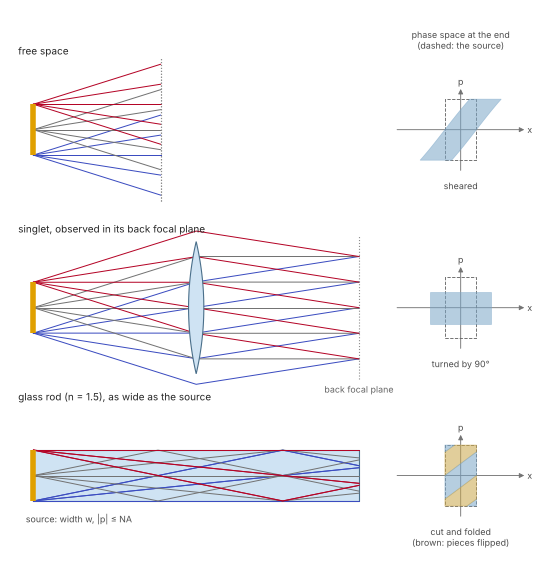

In [2]:
fig, ax = plt.subplots(figsize=(12, 9))
sketch.phase_space_portraits(ax)
plt.show()

In [3]:
def meridional(x, p, n=1.0):
    """Rays in the x-z plane from positions x and direction sines p."""
    zeros = np.zeros_like(x)
    return np.column_stack([x, zeros, zeros]), il.directions_from_sines(p, zeros, n)


W1, NA1, N1 = 2.0, 0.3, 1_000_000
x0 = (rng.random(N1) - 0.5)*W1          # a strip of width 2 mm ...
p0 = (2*rng.random(N1) - 1)*NA1         # ... that emits uniformly in p: the 2D Lambertian source
P0, d0 = meridional(x0, p0)

# free space, 10 mm
x_free = il.propagate(P0, d0, 10.0)[:, 0]

# a plano-convex singlet (f = 20.6 mm, n = 1.5) 20 mm behind the source, phase space in its back focal plane
singlet = rt.System([rt.Surface(10.3, 4.0, n_after=1.5, semi_diameter=9.0),
                     rt.Surface(np.inf, 20.6 - 4.0/1.5, semi_diameter=9.0)],
                    0, 550e-6, object_distance=20.0, object_height=1.0)
Y_lens = il.system_phase_map(singlet, np.column_stack([x0, 0*x0, p0, 0*p0]), z_in=-20.0)

# a glass rod (n = 1.5) of the width of the source, 60 mm long
P_rod, d_rod, k_rod = il.light_pipe(P0, d0, W1, 60.0, n_pipe=1.5)

stages = {"source": (x0, p0),
          "10 mm of free space": (x_free, p0),
          "back focal plane of a singlet": (Y_lens[:, 0], Y_lens[:, 2]),
          "exit of a 60 mm glass rod": (P_rod[:, 0], d_rod[:, 0])}
G1 = {}
for name, (x, p) in stages.items():
    ok = np.isfinite(x)
    rx, rp = np.nanmax(np.abs(x))*1.02, np.nanmax(np.abs(p))*1.02
    G1[name] = il.effective_etendue(np.column_stack([x, p]), 800, [(-rx, rx), (-rp, rp)])
    print("{:32s} transmitted {:.4f}, G_eff = {:.4f} mm".format(name, ok.mean(), G1[name]))
print("analytic: G = 2 w NA = {:.4f} mm".format(il.etendue_2d(W1, NA1)))

source                           transmitted 1.0000, G_eff = 1.2023 mm


10 mm of free space              transmitted 1.0000, G_eff = 1.2040 mm


back focal plane of a singlet    transmitted 0.9998, G_eff = 1.2065 mm


exit of a 60 mm glass rod        transmitted 1.0000, G_eff = 1.2023 mm
analytic: G = 2 w NA = 1.2000 mm


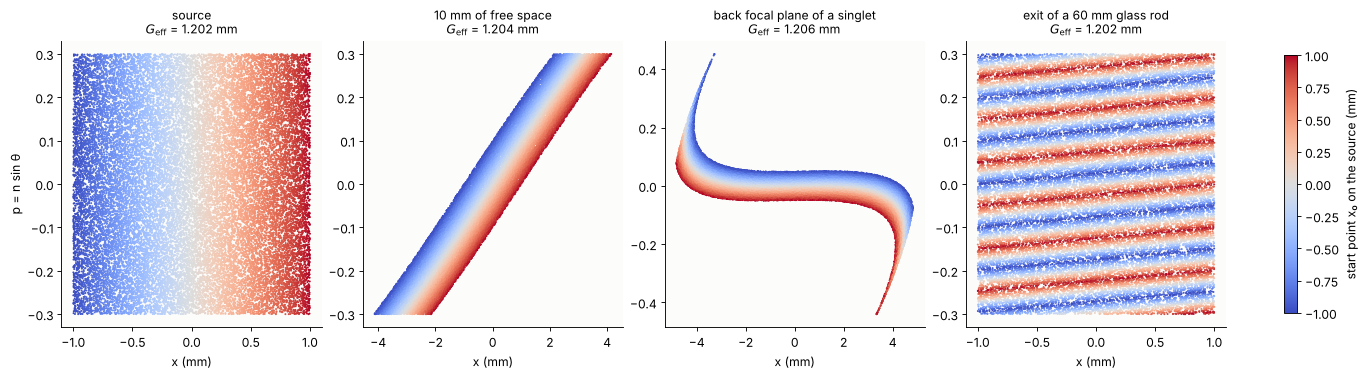

In [4]:
sub = slice(0, 30000)
fig, ax = plt.subplots(1, 4, figsize=(17, 4.6), layout="constrained")
for a, (name, (x, p)) in zip(ax, stages.items()):
    sc = a.scatter(x[sub], p[sub], c=x0[sub], s=0.6, cmap="coolwarm", vmin=-1, vmax=1, rasterized=True)
    a.set_title("{}\n$G_\\mathrm{{eff}}$ = {:.3f} mm".format(name, G1[name]), fontsize=11)
    a.set_xlabel("x (mm)")
ax[0].set_ylabel("p = n sin θ")
fig.colorbar(sc, ax=ax, label="start point x₀ on the source (mm)", shrink=0.9)
plt.show()

The shapes differ completely, the areas do not: all four are within
0.5 % of $2w\,\mathrm{NA} = 1.2$ mm, the residue being the bins cut by the
edges of the thin sheared and folded shapes. The singlet turns the
rectangle by 90° (positions in its back focal plane are $f p$ of the
source, directions are $-x/f$), and its spherical aberration bends the
image into an S without changing its area. The rod folds the strip into
stripes: every point of its exit face gets light from every part of the
source (the colours mix), which is why rods homogenize, but the occupied
area stays the same. No passive optics can pack the stripes closer.

## 2. Liouville's theorem in a real lens

Caldwell's all-silica KrF lens (notebook 19) images a field of 46.8 mm
radius 4× reduced; we fill its object field with a Lambertian source of
$\mathrm{NA} = 0.13$. The Jacobian of the full 4D ray map from object to
image (`il.system_phase_map()`, central differences in
`il.phase_space_jacobian()`) is symplectic to the accuracy of the
differences, at 2000 random rays through 18 aberrated surfaces. In a
rotationally symmetric system the **skew invariant** $h = n(xM - yL)$, the
angular momentum of the ray about the axis, is conserved separately
(`il.skew_invariant()`); it will limit the 3D concentrators of the next
notebook. The 4× smaller field comes with a 4× larger NA, the Lagrange
invariant of paraxial optics in its exact, nonparaxial form.

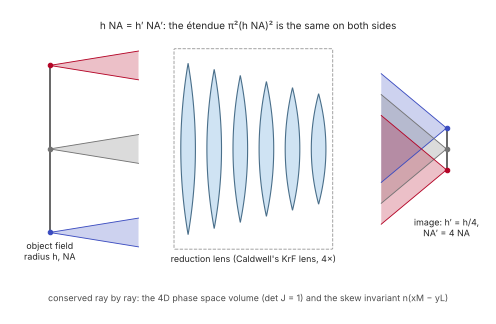

In [5]:
fig, ax = plt.subplots(figsize=(11, 5))
sketch.liouville_lens(ax)
plt.show()

In [6]:
caldwell = rt.caldwell_krf_lens()
r_obj, na_obj = caldwell.max_field, 0.13
print("Caldwell lens: object field radius {:.1f} mm, magnification {:.4f}, NA_image = 4 NA_object = {:.3f}"
      .format(r_obj, caldwell.paraxial().magnification, na_obj/abs(caldwell.paraxial().magnification)))
cmap = lambda X: il.system_phase_map(caldwell, X, z_in=-caldwell.object_distance)

X2 = np.column_stack([il.disk_points(2000, r_obj, rng), il.disk_points(2000, na_obj, rng)])
J2 = il.phase_space_jacobian(cmap, X2, h=np.array([1e-4, 1e-4, 1e-6, 1e-6]))
det2 = np.linalg.det(J2)
print("2000 random rays: |det J - 1| <= {:.1e}, |J^T Omega J - Omega| <= {:.1e}"
      .format(np.nanmax(np.abs(det2 - 1)), np.nanmax(il.symplectic_defect(J2))))

src2 = il.LambertianSource(r_obj, na=na_obj, z=-caldwell.object_distance)
R2 = src2.rays(1_000_000, rng)
B2 = caldwell.trace(R2)
Q2, e2 = caldwell.to_image_frame(B2.points[-1], B2.directions[-1])
X_obj = il.phase_space(R2.points, R2.directions)
X_img = il.phase_space(Q2, e2, B2.n[-1])
print("vignetted: {:.2e}".format(np.mean(np.isnan(X_img[:, 0]))))
h_obj = il.skew_invariant(R2.points, R2.directions)
h_img = il.skew_invariant(Q2, e2, B2.n[-1])
print("skew invariant: max |h_img - h_obj| = {:.1e} (max |h| = {:.2f} mm)"
      .format(np.nanmax(np.abs(h_img - h_obj)), np.max(np.abs(h_obj))))
r_img = np.nanmax(np.hypot(X_img[:, 0], X_img[:, 1]))
na_img = np.nanmax(np.hypot(X_img[:, 2], X_img[:, 3]))
G_obj = il.effective_etendue(X_obj, 32, [(-1.01*r_obj, 1.01*r_obj)]*2 + [(-1.01*na_obj, 1.01*na_obj)]*2)
G_img = il.effective_etendue(X_img, 32, [(-1.01*r_img, 1.01*r_img)]*2 + [(-1.01*na_img, 1.01*na_img)]*2)
print("object: r = {:.2f} mm, NA = {:.3f}; image: r = {:.2f} mm, NA = {:.3f}".format(r_obj, na_obj, r_img, na_img))
print("pi^2 (r NA)^2 of the object: {:.1f} mm^2; G_eff from the rays: object {:.1f}, image {:.1f} mm^2"
      .format(src2.etendue, G_obj, G_img))

Caldwell lens: object field radius 46.8 mm, magnification -0.2500, NA_image = 4 NA_object = 0.520
2000 random rays: |det J - 1| <= 1.5e-08, |J^T Omega J - Omega| <= 1.4e-06


vignetted: 3.40e-04
skew invariant: max |h_img - h_obj| = 3.2e-14 (max |h| = 6.06 mm)


object: r = 46.80 mm, NA = 0.130; image: r = 11.70 mm, NA = 0.531
pi^2 (r NA)^2 of the object: 365.3 mm^2; G_eff from the rays: object 382.2, image 381.9 mm^2


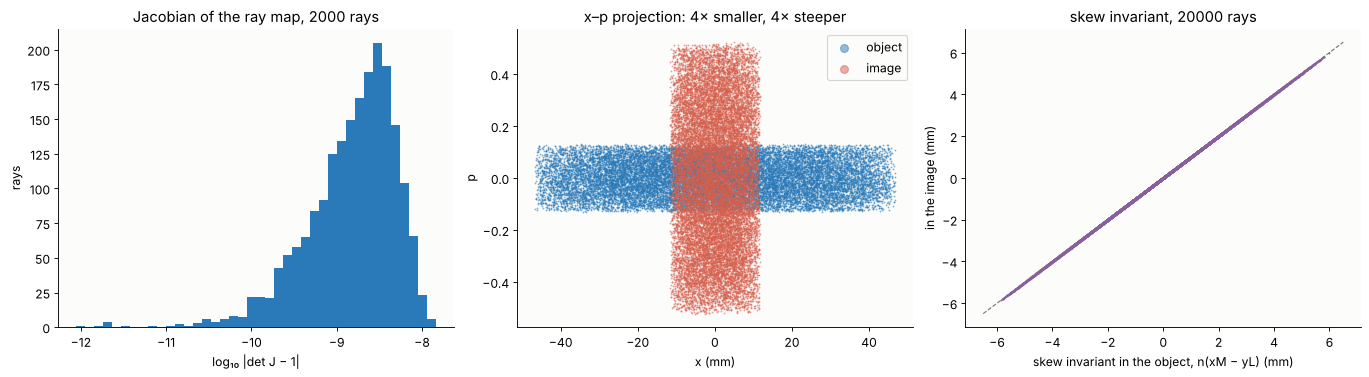

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.6), layout="constrained")
ax[0].hist(np.log10(np.abs(det2 - 1) + 1e-16), bins=40, color=BLUE)
ax[0].set_xlabel("log₁₀ |det J − 1|")
ax[0].set_ylabel("rays")
ax[0].set_title("Jacobian of the ray map, 2000 rays")
s = slice(0, 20000)
ax[1].scatter(X_obj[s, 0], X_obj[s, 2], s=0.5, color=BLUE, alpha=0.5, rasterized=True, label="object")
ax[1].scatter(X_img[s, 0], X_img[s, 2], s=0.5, color=RED, alpha=0.5, rasterized=True, label="image")
ax[1].set_xlabel("x (mm)")
ax[1].set_ylabel("p")
ax[1].set_title("x–p projection: 4× smaller, 4× steeper")
ax[1].legend(markerscale=10, loc="upper right")
ax[2].scatter(h_obj[s], h_img[s], s=0.5, color=PURPLE, rasterized=True)
ax[2].plot([-6.5, 6.5], [-6.5, 6.5], "--", color=GREY, lw=1)
ax[2].set_xlabel("skew invariant in the object, n(xM − yL) (mm)")
ax[2].set_ylabel("in the image (mm)")
ax[2].set_title("skew invariant, 20000 rays")
plt.show()

$\det J$ deviates from 1 by $10^{-8}$, the truncation and rounding error of
the central differences; the skew invariant agrees to $10^{-14}$. The
effective étendue of the million rays is the same in object and image
space; both are 5 % above $\pi^2(r\,\mathrm{NA})^2$ because a 4D histogram
with 32 bins per axis cuts many bins at the rims of the two disks (the
estimator is biased high at the boundary of a beam, by the same amount
before and after the lens).

## 3. The paraxial ideal lens violates Liouville

Lens design programs offer an ideal (paraxial) lens: a plane that bends
every ray towards the point where the parallel chief ray meets the focal
plane, $x' = f\tan\theta$, and corrects the optical path so that every
field is a perfect focus (`rt.IdealLens`). It is extremely useful, but it
is not a physical lens. A ray at the height $h$ leaves it at the angle
$\tan\theta' = h/f$; the map from the lens to its focal plane has, in 2D,
$\partial x'/\partial p = f/(1 - p^2)^{3/2}$ and
$\partial p'/\partial h = -\cos^3\theta'/f$, so for a ray parallel to the axis

$$\det J_\text{2D} = \cos^3\theta', \qquad \det J_\text{4D} = \cos^4\theta'$$

(the sagittal direction contributes another $\cos\theta'$). The ideal lens
compresses phase space at large apertures. A physical lens that images an
object at infinity perfectly at every field angle would have to obey
$x' = f\tan\theta$ *and* Abbe's sine condition $h = f\sin\theta'$; the two
together are impossible, and the sine condition is precisely the
condition that keeps the phase space volume of every small pencil.

The test: a hyperbolic plano-convex lens (flat side to the light, conic
constant $K = -n^2$, stigmatic on axis), traced exactly, against the ideal
lens, both $f = 50$ mm, as burning glasses in sunlight. Sunlight is a
Lambertian source with $\sin\alpha = 4.65\times 10^{-3}$
(`il.LambertianSource(a, na=np.sin(il.SUN_ANGULAR_RADIUS))` on the
aperture). Since every direction in the cone that converges onto the axial
focus comes from inside the solar disk, the brightness theorem gives the
peak irradiance exactly,

$$C_\text{peak} = \frac{E(0)}{E_\odot} = \frac{\pi L\sin^2\theta'}{\pi L\sin^2\alpha}
 = \frac{\mathrm{NA}'^2}{\sin^2\alpha},$$

with the NA of the marginal ray. The ideal lens raises the radiance by
$1/\det J = 1/\cos^4\theta'$, which adds up to
$C_\text{peak} = \tan^2\theta'/\sin^2\alpha$.

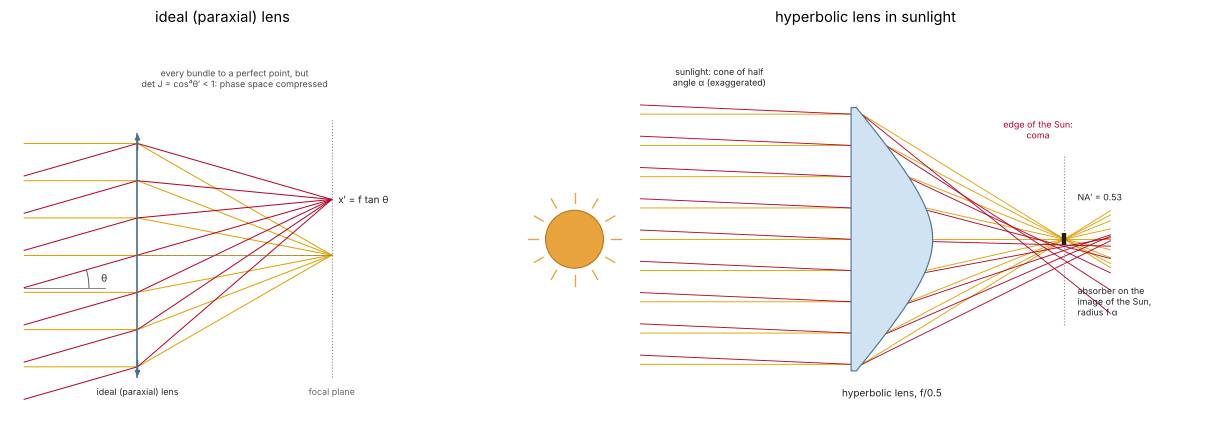

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(16, 5.2), layout="constrained", width_ratios=[1, 1.2])
sketch.burning_glass(ax[0], lens="ideal", title="ideal (paraxial) lens")
sketch.burning_glass(ax[1], title="hyperbolic lens in sunlight")
plt.show()

In [9]:
F = 50.0
ideal = rt.System([rt.IdealLens(F, F, semi_diameter=200.0)], 0, 550e-6)
imap = lambda X: il.system_phase_map(ideal, X, z_in=-1.0)
h3 = np.linspace(0, 2*F, 41)
X3 = np.column_stack([h3, 0*h3, 0*h3, 0*h3])
det_4d = np.linalg.det(il.phase_space_jacobian(imap, X3, h=1e-5))
det_2d = np.linalg.det(il.phase_space_jacobian(lambda X: imap(np.column_stack([X[:, 0], 0*X[:, 0], X[:, 1], 0*X[:, 0]]))[:, [0, 2]],
                                               X3[:, [0, 2]], h=1e-5))
cos_out = F/np.hypot(F, h3)
print("ideal lens at h = f: det (2D) = {:.4f} (cos^3 = {:.4f}), det (4D) = {:.4f} (cos^4 = {:.4f})"
      .format(det_2d[20], cos_out[20]**3, det_4d[20], cos_out[20]**4))

def hyperbolic_lens(a, f=F, n=1.5):
    """Plano-convex lens, flat side to the light, hyperbolic back (K = -n^2): stigmatic on axis."""
    R, K = -(n - 1)*f, -n**2
    c = 1/R
    sag = c*a**2/(1 + np.sqrt(1 - (1 + K)*c**2*a**2))
    return rt.System([rt.Surface(np.inf, abs(sag) + 2.0, n_after=n, semi_diameter=a),
                      rt.Surface(R, f, n_after=1.0, conic=K)], 0, 550e-6)

hmap = lambda X: il.system_phase_map(hyperbolic_lens(80.0), X, z_in=-1.0)
det_h = np.linalg.det(il.phase_space_jacobian(hmap, X3[h3 < 80], h=1e-5))
print("hyperbolic lens: max |det - 1| = {:.1e}".format(np.nanmax(np.abs(det_h - 1))))

def sun_spot(system, a, n_rays=1_000_000):
    """Trace sunlight through an aperture of radius a; points and directions in the focal plane."""
    R = il.LambertianSource(a, na=np.sin(ALPHA), z=-1.0).rays(n_rays, rng)
    B = system.trace(R)
    return system.to_image_frame(B.points[-1], B.directions[-1])

def peak_concentration(Q, a, r0=0.5*F*ALPHA):
    """Mean irradiance (over that of sunlight) within r0 of the axis."""
    return np.mean(np.hypot(Q[:, 0], Q[:, 1]) < r0)*a**2/r0**2

def marginal_na(system, a):
    """NA of the axial marginal ray at the focus."""
    B = system.trace(rt.Rays(np.array([[0.0, a*(1 - 1e-9), -1.0]]), np.array([[0.0, 0.0, 1.0]]), np.zeros(1)))
    e = system.to_image_frame(B.points[-1], B.directions[-1])[1]
    return np.hypot(e[0, 0], e[0, 1])

apertures = np.array([5, 10, 20, 30, 40, 50, 60, 80, 100, 130])
C_ideal, na_ideal, C_hyp, na_hyp, T_hyp = [], [], [], [], []
for a in apertures:
    Q, e = sun_spot(ideal, a, 400_000)
    C_ideal.append(peak_concentration(Q, a))
    na_ideal.append(marginal_na(ideal, a))
    lens = hyperbolic_lens(a)
    Q, e = sun_spot(lens, a, 400_000)
    T_hyp.append(np.mean(np.isfinite(Q[:, 0])))
    C_hyp.append(peak_concentration(Q, a))
    na_hyp.append(marginal_na(lens, a))
C_ideal, na_ideal, C_hyp, na_hyp, T_hyp = map(np.array, (C_ideal, na_ideal, C_hyp, na_hyp, T_hyp))
for a, c, s, t in zip(apertures, C_hyp, na_hyp, T_hyp):
    print("hyperbolic lens, a = {:3d} mm (f/{:.2f}): NA' = {:.3f}, transmitted {:.3f}, C_peak = {:6.0f}, NA'^2/sin^2(alpha) = {:6.0f}"
          .format(a, F/(2*a), s, t, c, s**2/np.sin(ALPHA)**2))
for a, c, s in zip(apertures, C_ideal, na_ideal):
    th = np.arcsin(s)
    print("ideal lens, a = {:3d} mm: NA' = {:.3f}, C_peak = {:8.0f}, tan^2/sin^2(alpha) = {:8.0f}"
          .format(a, s, c, np.tan(th)**2/np.sin(ALPHA)**2))

ideal lens at h = f: det (2D) = 0.3536 (cos^3 = 0.3536), det (4D) = 0.2500 (cos^4 = 0.2500)
hyperbolic lens: max |det - 1| = 2.1e-08


hyperbolic lens, a =   5 mm (f/5.00): NA' = 0.099, transmitted 1.000, C_peak =    449, NA'^2/sin^2(alpha) =    449
hyperbolic lens, a =  10 mm (f/2.50): NA' = 0.189, transmitted 1.000, C_peak =   1649, NA'^2/sin^2(alpha) =   1653
hyperbolic lens, a =  20 mm (f/1.25): NA' = 0.332, transmitted 1.000, C_peak =   5116, NA'^2/sin^2(alpha) =   5091
hyperbolic lens, a =  30 mm (f/0.83): NA' = 0.427, transmitted 1.000, C_peak =   8423, NA'^2/sin^2(alpha) =   8438
hyperbolic lens, a =  40 mm (f/0.62): NA' = 0.491, transmitted 1.000, C_peak =  11167, NA'^2/sin^2(alpha) =  11135
hyperbolic lens, a =  50 mm (f/0.50): NA' = 0.535, transmitted 1.000, C_peak =  13172, NA'^2/sin^2(alpha) =  13217
hyperbolic lens, a =  60 mm (f/0.42): NA' = 0.567, transmitted 1.000, C_peak =  14765, NA'^2/sin^2(alpha) =  14830
hyperbolic lens, a =  80 mm (f/0.31): NA' = 0.609, transmitted 1.000, C_peak =  17244, NA'^2/sin^2(alpha) =  17115
hyperbolic lens, a = 100 mm (f/0.25): NA' = 0.635, transmitted 1.000, C_peak =  

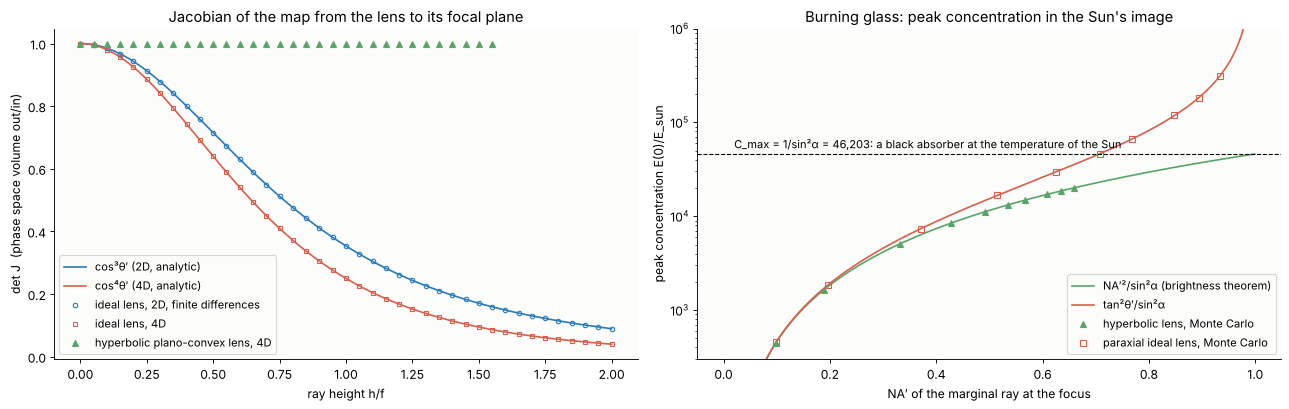

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(16, 5), layout="constrained")
hh = np.linspace(0, 2*F, 400)
cc = F/np.hypot(F, hh)
ax[0].plot(hh/F, cc**3, color=BLUE, lw=1.5, label="cos³θ′ (2D, analytic)")
ax[0].plot(hh/F, cc**4, color=RED, lw=1.5, label="cos⁴θ′ (4D, analytic)")
ax[0].plot(h3/F, det_2d, "o", color=BLUE, ms=4, mfc="none", label="ideal lens, 2D, finite differences")
ax[0].plot(h3/F, det_4d, "s", color=RED, ms=4, mfc="none", label="ideal lens, 4D")
ax[0].plot(h3[h3 < 80]/F, det_h, "^", color=GREEN, ms=5, label="hyperbolic plano-convex lens, 4D")
ax[0].set_xlabel("ray height h/f")
ax[0].set_ylabel("det J  (phase space volume out/in)")
ax[0].set_title("Jacobian of the map from the lens to its focal plane")
ax[0].legend(fontsize=10)

s = np.linspace(0, 0.999, 400)
C_max = il.concentration_limit(ALPHA)
ax[1].plot(s, s**2/np.sin(ALPHA)**2, color=GREEN, lw=1.5, label="NA′²/sin²α (brightness theorem)")
ax[1].plot(s, s**2/(1 - s**2)/np.sin(ALPHA)**2, color=RED, lw=1.5, label="tan²θ′/sin²α")
ax[1].plot(na_hyp, C_hyp, "^", color=GREEN, ms=6, label="hyperbolic lens, Monte Carlo")
ax[1].plot(na_ideal, C_ideal, "s", color=RED, ms=5, mfc="none", label="paraxial ideal lens, Monte Carlo")
ax[1].axhline(C_max, color="k", lw=1, ls="--")
ax[1].text(0.02, C_max*1.15, "C_max = 1/sin²α = {:,.0f}: a black absorber at the temperature of the Sun".format(C_max),
           fontsize=10)
ax[1].set_yscale("log")
ax[1].set_ylim(300, 1e6)
ax[1].set_xlabel("NA′ of the marginal ray at the focus")
ax[1].set_ylabel("peak concentration E(0)/E_sun")
ax[1].set_title("Burning glass: peak concentration in the Sun's image")
ax[1].legend(fontsize=10, loc="lower right")
plt.show()

The Monte Carlo concentrations (mean irradiance within $f\alpha/2$ of the
axis) agree with the formulas to the noise, 1 % or better, and the
Jacobians with $\cos^3\theta'$ and $\cos^4\theta'$ to rounding. The real
lens stays below $C_\max$ at any aperture: as the aperture grows, the
marginal ray of a hyperbolic lens approaches the asymptote of the
hyperbola, where it grazes the surface at the critical angle, and the NA
saturates at $\sqrt{1 - 1/n^2} = 0.745$, i.e. $C \to 25{,}700$. The ideal
lens crosses $C_\max$ at f/0.5 ($\tan\theta' = 1$): an f/0.4 ideal lens
would heat a black absorber above the surface temperature of the Sun, a
perpetual motion machine of the second kind. Use ideal lenses for
paraxial layouts and imaging at modest NA, never to compute illuminance or
concentration at high NA.

## 4. A burning glass

The peak tells only half the story. An absorber has a size, and a lens
that does not obey the sine condition smears the off-axis points of the
Sun's image with coma. We trace two million solar rays through the
hyperbolic lens at f/0.5 ($a = f = 50$ mm) and compute the irradiance in
the focal plane and the mean concentration on a round absorber against its
radius. The stagnation temperature of a black absorber in vacuum, which
loses heat only by its own radiation, follows from
$\sigma T^4 = C\,E_\odot$ with $E_\odot = \sigma T_\odot^4/C_\max$:

$$T = T_\odot\left(\frac{C}{C_\max}\right)^{1/4}$$

(`il.concentration_temperature()`, $T_\odot = 5772$ K; 394 K for direct
sunlight on a black plate).

In [11]:
a4 = 50.0
lens4 = hyperbolic_lens(a4)
Q4, e4 = sun_spot(lens4, a4, 2_000_000)
r4 = np.hypot(Q4[:, 0], Q4[:, 1])
ok4 = np.isfinite(r4)
edges = np.linspace(0, 6*F*ALPHA, 121)
counts, _ = np.histogram(r4[ok4], bins=edges)
rc = 0.5*(edges[1:] + edges[:-1])
E_r = counts/len(r4)*a4**2/(edges[1:]**2 - edges[:-1]**2)   # irradiance over that of sunlight
rs = np.sort(r4[ok4])
enc = np.arange(1, len(rs) + 1)/len(r4)
C_mean = enc*a4**2/rs**2
T_abs = il.concentration_temperature(C_mean)
i_best = np.argmax(C_mean*(rs > 0.05*F*ALPHA))
na4 = marginal_na(lens4, a4)
print("a = {} mm, f/{:.2f}, NA' = {:.3f}: C_peak = {:.0f} (within f alpha/2), NA'^2/sin^2(alpha) = {:.0f}"
      .format(a4, F/(2*a4), na4, peak_concentration(Q4, a4), na4**2/np.sin(ALPHA)**2))
print("fraction of the light within the paraxial Sun image r < f alpha: {:.3f}".format(np.mean(r4 < F*ALPHA)))
for frac in (0.5, 0.8, 0.9, 0.95):
    j = np.searchsorted(enc, frac)
    print("absorber with {:.0%} of the power: radius {:.3f} mm = {:.2f} f alpha, mean C = {:6.0f}, T = {:4.0f} K"
          .format(frac, rs[j], rs[j]/(F*ALPHA), C_mean[j], T_abs[j]))
print("sunlight on a black plate (C = 1): {:.0f} K".format(il.concentration_temperature(1.0)))

a = 50.0 mm, f/0.50, NA' = 0.535: C_peak = 13185 (within f alpha/2), NA'^2/sin^2(alpha) = 13217
fraction of the light within the paraxial Sun image r < f alpha: 0.286
absorber with 50% of the power: radius 0.328 mm = 1.41 f alpha, mean C =  11637, T = 4089 K
absorber with 80% of the power: radius 0.552 mm = 2.38 f alpha, mean C =   6552, T = 3542 K
absorber with 90% of the power: radius 0.705 mm = 3.03 f alpha, mean C =   4530, T = 3230 K
absorber with 95% of the power: radius 0.830 mm = 3.57 f alpha, mean C =   3446, T = 3016 K
sunlight on a black plate (C = 1): 394 K


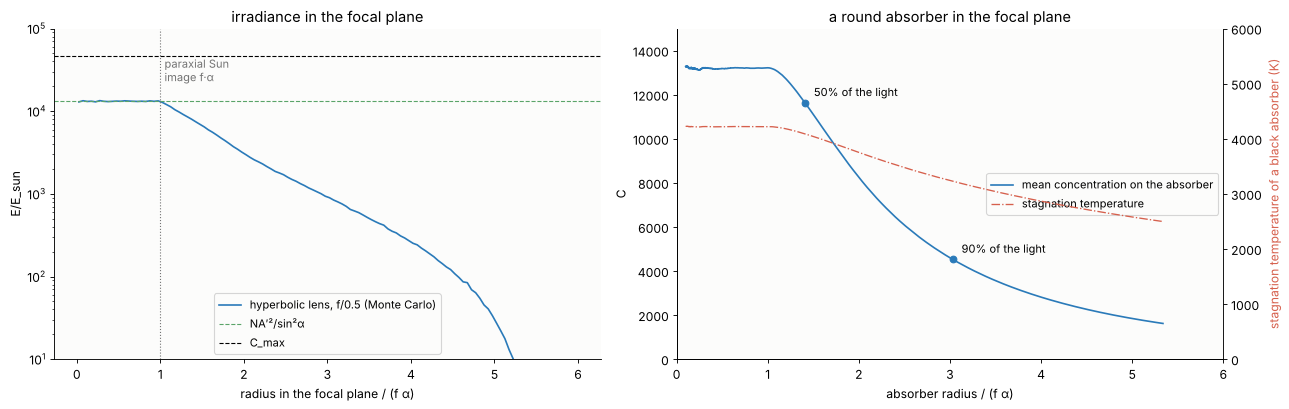

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(16, 5), layout="constrained")
ax[0].plot(rc/(F*ALPHA), E_r, color=BLUE, lw=1.5, label="hyperbolic lens, f/0.5 (Monte Carlo)")
ax[0].axhline(na4**2/np.sin(ALPHA)**2, color=GREEN, ls="--", lw=1, label="NA′²/sin²α")
ax[0].axhline(C_max, color="k", ls="--", lw=1, label="C_max")
ax[0].axvline(1, color=GREY, ls=":", lw=1)
ax[0].text(1.05, 0.5*C_max, "paraxial Sun\nimage f·α", fontsize=10, color=GREY)
ax[0].set_xlabel("radius in the focal plane / (f α)")
ax[0].set_ylabel("E/E_sun")
ax[0].set_yscale("log")
ax[0].set_ylim(10, 1e5)
ax[0].set_title("irradiance in the focal plane")
ax[0].legend(fontsize=10)
sel = slice(np.searchsorted(rs, 0.1*F*ALPHA), None, 200)
ax[1].plot(rs[sel]/(F*ALPHA), C_mean[sel], color=BLUE, lw=1.5, label="mean concentration on the absorber")
for frac in (0.5, 0.9):
    j = np.searchsorted(enc, frac)
    ax[1].plot(rs[j]/(F*ALPHA), C_mean[j], "o", color=BLUE)
    ax[1].annotate("{:.0%} of the light".format(frac), (rs[j]/(F*ALPHA), C_mean[j]), xytext=(8, 6),
                   textcoords="offset points", fontsize=10)
ax[1].set_ylim(0, 15000)
ax[1].set_xlabel("absorber radius / (f α)")
ax[1].set_ylabel("C")
ax[1].set_xlim(0, 6)
ax[1].set_title("a round absorber in the focal plane")
tw = ax[1].twinx()
tw.plot(rs[sel]/(F*ALPHA), T_abs[sel], color=RED, lw=1.2, ls="-.", label="stagnation temperature")
tw.set_ylabel("stagnation temperature of a black absorber (K)", color=RED)
tw.spines["right"].set_visible(True)
tw.set_ylim(0, 6000)
h1, l1 = ax[1].get_legend_handles_labels()
h2, l2 = tw.get_legend_handles_labels()
ax[1].legend(h1 + h2, l1 + l2, fontsize=10, loc="center right")
plt.show()

Inside the paraxial image of the Sun ($r < f\alpha$, 0.23 mm) the
irradiance is flat at the brightness bound $\mathrm{NA}'^2/\sin^2\alpha$:
each point there still sees the full cone of the lens filled with sunlight.
Outside, coma spreads the light over five times the radius. An absorber
that just covers $f\alpha$ would get only 29 % of the light; one that takes
90 % must be 3 times larger and gets a mean concentration of about 4500,
a stagnation temperature of 3200 K, which still melts any metal. To get
closer to 5772 K, the optics must fill the absorber's whole hemisphere with
sunlight, $\mathrm{NA}' \to 1$, which lenses cannot do. The compound parabolic
concentrator does, by giving up imaging: that is the subject of the next
notebook. Immersing the absorber in glass raises the limit to
$n^2/\sin^2\alpha$ (`il.concentration_limit(alpha, n=1.5)` = 104,000),
since the basic radiance $L/n^2$ is what is conserved: the radiance in
glass is $n^2$ times that in air.

## 5. Apertures, diffusers and the étendue of a laser beam

Losses are the only way to reduce étendue, and they cost power in the same
proportion: a slit of 1 mm on the 2 mm source of section 1 halves both,
and the radiance $P/G$ stays the same. Diffusers enlarge the étendue. For a
Gaussian distribution in phase space with the covariance matrix $\Sigma$,
$\int L^2 = P^2/(4\pi\sqrt{\det\Sigma})$, so

$$G_\mathrm{eff} = 4\pi\sqrt{\det\Sigma}$$

in 2D. Free space shears $\Sigma$ without changing its determinant; a thin
diffuser that adds direction sines with the rms spread $\sigma_d$ adds
$\sigma_d^2$ to $\Sigma_{pp}$, and the determinant grows by
$\sigma_d^2\Sigma_{xx}$:

$$G_\mathrm{eff} = 4\pi\sqrt{\sigma_x^2\sigma_p^2 + \sigma_d^2\,\sigma_{x}(z)^2}.$$

The same diffuser makes more étendue where the beam is wide. A beam of
$\sigma_x = 1$ mm and $\sigma_p = 0.02$ gets a diffuser at its waist or
50 mm further on, where it has spread to $\sigma_x = 1.41$ mm.

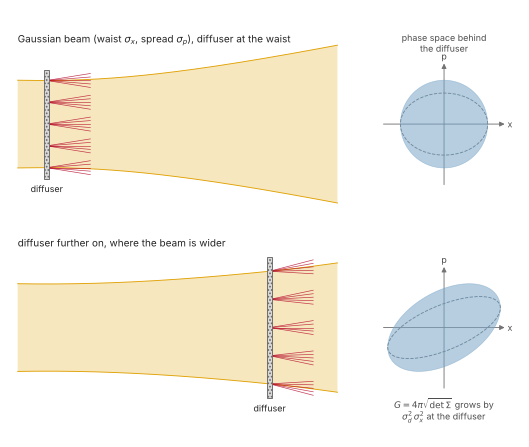

In [13]:
fig, ax = plt.subplots(figsize=(12, 7))
sketch.etendue_diffuser(ax)
plt.show()

In [14]:
N5 = 1_000_000
SX, SP, Z5 = 1.0, 0.02, 50.0
xg, pg = SX*rng.standard_normal(N5), SP*rng.standard_normal(N5)
Pg, dg = meridional(xg, pg)
Pz = il.propagate(Pg, dg, Z5)
sx_z = np.std(Pz[:, 0])

def diffused_etendue(P, d, sd):
    d2 = il.diffuse(d, sd, rng=rng)
    d2 = il.directions_from_sines(d2[:, 0], 0*d2[:, 0])
    x, p = P[:, 0], d2[:, 0]
    return il.effective_etendue(np.column_stack([x, p]), 500, [(-7*np.std(x), 7*np.std(x)), (-7*np.nanstd(p), 7*np.nanstd(p))]), x, p

sd_list = np.array([0.0, 0.01, 0.02, 0.04, 0.06, 0.08, 0.1])
G_waist = np.array([diffused_etendue(Pg, dg, sd)[0] for sd in sd_list])
G_far = np.array([diffused_etendue(Pz, dg, sd)[0] for sd in sd_list])
_, x_a, p_a = diffused_etendue(Pz, dg, 0.0)
_, x_b, p_b = diffused_etendue(Pz, dg, 0.04)
print("Gaussian beam: G = 4 pi sigma_x sigma_p = {:.4f} mm, Monte Carlo {:.4f} mm (waist), {:.4f} mm (after {} mm)"
      .format(4*np.pi*SX*SP, G_waist[0], G_far[0], Z5))
print("beam radius sigma_x at the second diffuser position: {:.3f} mm".format(sx_z))
# an aperture: radiance stays, power and étendue drop together
cut = np.abs(x0) < 0.5
P_cut = cut.mean()
G_cut = il.effective_etendue(np.column_stack([x0[cut], p0[cut]]), 800, [(-1.02, 1.02), (-0.306, 0.306)],
                             weights=np.full(cut.sum(), 1/N1))
print("slit of 1 mm on the 2 mm source: power {:.3f}, G_eff {:.3f} mm, radiance P/G: {:.4f} -> {:.4f}"
      .format(P_cut, G_cut, 1/G1["source"], P_cut/G_cut))
WL = 633e-6
print("TEM00, w0 = 2 mm, 633 nm: sigma_x sigma_p = lambda/(4 pi) -> G = {:.2e} mm = lambda".format(4*np.pi*1.0*WL/(4*np.pi*1.0)))

Gaussian beam: G = 4 pi sigma_x sigma_p = 0.2513 mm, Monte Carlo 0.2509 mm (waist), 0.2509 mm (after 50.0 mm)
beam radius sigma_x at the second diffuser position: 1.414 mm
slit of 1 mm on the 2 mm source: power 0.500, G_eff 0.602 mm, radiance P/G: 0.8317 -> 0.8310
TEM00, w0 = 2 mm, 633 nm: sigma_x sigma_p = lambda/(4 pi) -> G = 6.33e-04 mm = lambda


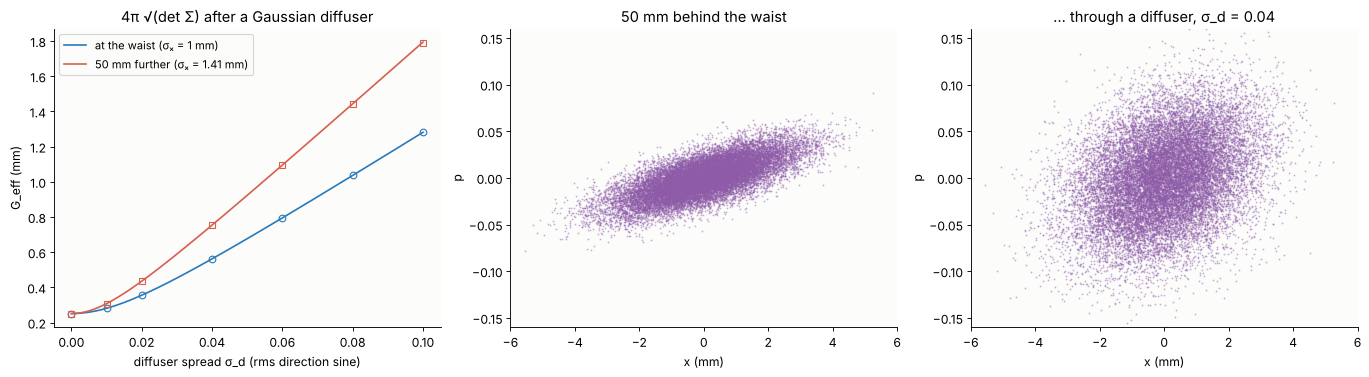

In [15]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.6), layout="constrained")
ss = np.linspace(0, 0.1, 200)
ax[0].plot(ss, 4*np.pi*np.sqrt(SX**2*SP**2 + ss**2*SX**2), color=BLUE, lw=1.5, label="at the waist (σₓ = 1 mm)")
ax[0].plot(ss, 4*np.pi*np.sqrt(SX**2*SP**2 + ss**2*sx_z**2), color=RED, lw=1.5,
           label="{:.0f} mm further (σₓ = {:.2f} mm)".format(Z5, sx_z))
ax[0].plot(sd_list, G_waist, "o", color=BLUE, mfc="none")
ax[0].plot(sd_list, G_far, "s", color=RED, mfc="none")
ax[0].set_xlabel("diffuser spread σ_d (rms direction sine)")
ax[0].set_ylabel("G_eff (mm)")
ax[0].set_title("4π √(det Σ) after a Gaussian diffuser")
ax[0].legend(fontsize=10)
s = slice(0, 20000)
for a, (x, p, t) in zip(ax[1:], [(x_a, p_a, "{:.0f} mm behind the waist".format(Z5)),
                                 (x_b, p_b, "... through a diffuser, σ_d = 0.04")]):
    a.scatter(x[s], p[s], s=0.5, color=PURPLE, alpha=0.4, rasterized=True)
    a.set_xlim(-6, 6)
    a.set_ylim(-0.16, 0.16)
    a.set_xlabel("x (mm)")
    a.set_ylabel("p")
    a.set_title(t)
plt.show()

The Monte Carlo agrees with $4\pi\sqrt{\det\Sigma}$ at every spread, and the
two curves differ by the ratio of the beam widths once the diffuser
dominates. In the phase space plots the tilted ellipse of the propagated
beam (its correlation of $x$ and $p$ is the wavefront curvature) is filled
up by the diffuser into a much larger, untilted one.

A coherent beam has an étendue too. The Wigner function of a TEM₀₀ beam
(notebook 47) is a Gaussian in phase space with
$\sigma_x\sigma_p = \lambda/4\pi$, so $G_\mathrm{eff} = \lambda$ in 2D
and $\lambda^2$ in 3D, and a beam of quality $M^2$ (notebook 07) has
$(M^2\lambda)^2$. In general $G_\mathrm{eff}/\lambda^2$ counts the spatial
modes a beam occupies: one for a laser, about $10^{7}$ for a 1 mm² LED in the visible.
A diffuser in a laser beam multiplies the modes by its étendue gain; how
many of them are mutually incoherent decides the speckle contrast, the
topic of a later notebook.

## 6. The light pipe: uniform field, diluted étendue

The KrF illuminator of notebook 42 mixes its light in a glass rod and needs
a diffuser in front of it, because without one the pupil shows a grid of
spots. Phase space explains both. We focus a 0.2 mm wide spot with
$|p| \le 0.3$ on the entrance of the 2 mm rod of section 1 and compare it
with the full 2 mm entrance.

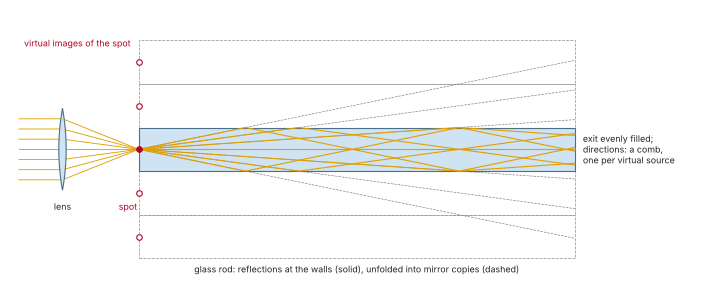

In [16]:
fig, ax = plt.subplots(figsize=(13, 4.6))
sketch.light_pipe_images(ax)
plt.show()

In [17]:
W6, L6, N_ROD = 2.0, 60.0, 1.5
s6 = 0.2
xs = (rng.random(N1) - 0.5)*s6
Ps, ds = meridional(xs, p0)
P_s, d_s, k_s = il.light_pipe(Ps, ds, W6, L6, n_pipe=N_ROD)
x_probe = 0.5
probe_s = np.abs(P_s[:, 0] - x_probe) < 0.01
probe_f = np.abs(P_rod[:, 0] - x_probe) < 0.01
m = np.arange(-20, 21)
t_m = (x_probe - m*W6)/L6                     # directions from the mirror images of the spot centre
p_m = N_ROD*np.sin(np.arctan(t_m))
p_m = p_m[np.abs(p_m) <= NA1]
G_spot = il.effective_etendue(np.column_stack([P_s[:, 0], d_s[:, 0]]), 1000, [(-1.01, 1.01), (-0.306, 0.306)])
print("spot of {} mm into the {} mm rod: G = {:.3f} mm (analytic {:.3f}), fill of the box 2 W NA: {:.2f}"
      .format(s6, W6, G_spot, il.etendue_2d(s6, NA1), G_spot/il.etendue_2d(W6, NA1)))
print("max reflections: {:.0f}; comb spacing in tan(theta) inside the rod W/L = {:.4f}".format(np.max(k_s[:, 0]), W6/L6))

spot of 0.2 mm into the 2.0 mm rod: G = 0.125 mm (analytic 0.120), fill of the box 2 W NA: 0.10
max reflections: 6; comb spacing in tan(theta) inside the rod W/L = 0.0333


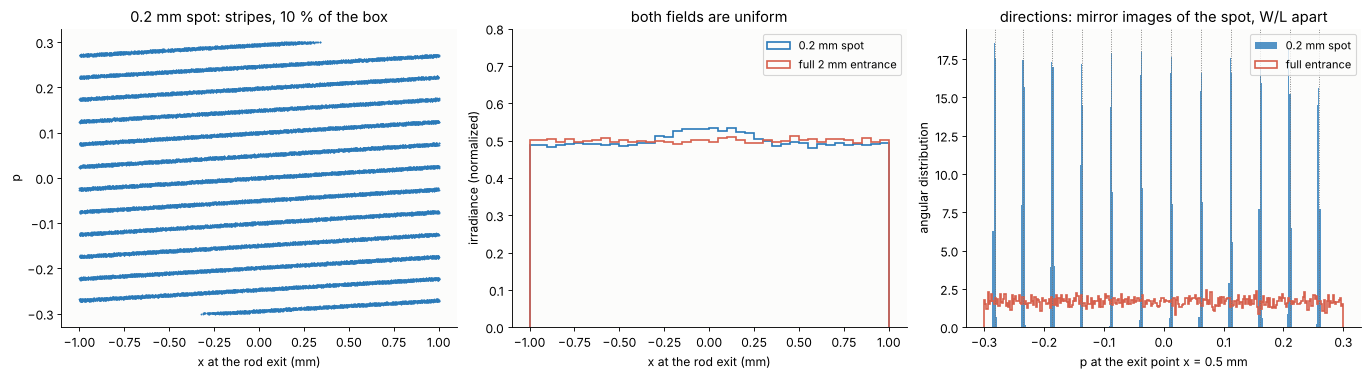

In [18]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.6), layout="constrained")
s = slice(0, 40000)
ax[0].scatter(P_s[s, 0], d_s[s, 0], s=0.4, color=BLUE, rasterized=True)
ax[0].set_xlabel("x at the rod exit (mm)")
ax[0].set_ylabel("p")
ax[0].set_title("0.2 mm spot: stripes, 10 % of the box")
bins = np.linspace(-1, 1, 41)
ax[1].hist(P_s[:, 0], bins=bins, density=True, histtype="step", color=BLUE, lw=1.5, label="0.2 mm spot")
ax[1].hist(P_rod[:, 0], bins=bins, density=True, histtype="step", color=RED, lw=1.5, label="full 2 mm entrance")
ax[1].set_ylim(0, 0.8)
ax[1].set_xlabel("x at the rod exit (mm)")
ax[1].set_ylabel("irradiance (normalized)")
ax[1].set_title("both fields are uniform")
ax[1].legend(fontsize=10)
pb = np.linspace(-NA1, NA1, 301)
ax[2].hist(d_s[probe_s, 0], bins=pb, density=True, color=BLUE, alpha=0.8, label="0.2 mm spot")
ax[2].hist(d_rod[probe_f, 0], bins=pb, density=True, histtype="step", color=RED, lw=1.5, label="full entrance")
for v in p_m:
    ax[2].axvline(v, color=GREY, lw=0.8, ls=":")
ax[2].set_xlabel("p at the exit point x = {} mm".format(x_probe))
ax[2].set_ylabel("angular distribution")
ax[2].set_title("directions: mirror images of the spot, W/L apart")
ax[2].legend(fontsize=10, loc="upper right")
plt.show()

Both exit faces are uniformly lit (the small bump of the spot comes from
the incomplete last fold at only six reflections). But the spot's
phase space at the exit is a set of thin stripes that fill only 10 % of
the box $|x| \le W/2$, $|p| \le 0.3$: the rod does not add étendue, it
only spreads the existing $2s\,\mathrm{NA}$ = 0.12 mm over the field (the estimate, 0.125 mm, is again biased high by the edges of the thin stripes). At any one point of the
exit face the directions form a comb: the rod is a kaleidoscope, a point
on the exit sees the mirror images of the spot at the positions $mW$, so
the directions inside the rod are $\tan\theta_m = (x - mW)/L$, $W/L$ apart
(dotted lines). The REMA objective images the exit face onto the reticle,
so the angular distribution at each reticle point, the pupil fill, is
this comb: the grid of spots in notebook 42. A diffuser that widens the
spot to the full entrance fills the gaps, and the price is étendue; this
is harmless only as long as the pupil fill (sigma) of the projection lens
accepts it. In étendue terms: the étendue of the source should match the
étendue that the target accepts, otherwise one either loses light
(source too large, `il.coupling_limit()`) or gets an uneven pupil (source
too small, unless diluted on purpose).

## Summary

- **Phase space:** the canonical coordinates
  $(x, y, p, q) = (x, y, nL, nM)$ (`il.phase_space()`) turn every optical
  system into a map of phase space. Free space shears it, a lens rotates
  it, a light pipe folds it; the area stays $2w\,\mathrm{NA}$ to 0.5 %
  (`il.effective_etendue()`, the participation étendue $P^2/\int L^2$).
- **Liouville:** the 4D Jacobian of Caldwell's 18-surface lithography lens
  is symplectic, $\det J = 1 \pm 10^{-8}$, and its skew invariant is
  conserved to $10^{-14}$ (`il.phase_space_jacobian()`,
  `il.system_phase_map()`, `il.skew_invariant()`). Field × NA is the same
  on both sides, $G$ = 382 mm² by Monte Carlo.
- **The ideal lens cheats:** the paraxial ideal lens has
  $\det J = \cos^4\theta'$ (2D: $\cos^3\theta'$), confirmed to rounding. Its
  peak concentration of sunlight, $\tan^2\theta'/\sin^2\alpha$, passes the
  thermodynamic limit $1/\sin^2\alpha$ = 46,200 at f/0.5.
- **Brightness theorem:** a stigmatic real lens reaches exactly
  $\mathrm{NA}'^2/\sin^2\alpha$ on axis (1 % agreement from f/5 to f/0.19);
  the hyperbolic singlet saturates at $\mathrm{NA}' = \sqrt{1 - 1/n^2}$.
  An f/0.5 burning glass delivers 13,200 suns on axis but, with coma, 4500
  suns on an absorber that collects 90 % of the light: 3200 K instead of
  the Sun's 5772 K (`il.concentration_temperature()`).
- **Étendue changes only with loss or scattering:** an aperture removes
  power and étendue in proportion (radiance unchanged); a diffuser adds
  $\sigma_d^2\Sigma_{xx}$ to $\det\Sigma$, $G = 4\pi\sqrt{\det\Sigma}$,
  more where the beam is wide. A TEM₀₀ beam has $G = \lambda$ (2D),
  $\lambda^2$ (3D).
- **Light pipes:** a rod makes the field uniform but not the pupil; a small
  input spot leaves a comb of directions $W/L$ apart (the spots in the pupil
  of notebook 42) and fills only its own share of the exit phase space.

The next notebooks use these tools for nonimaging concentrators (the CPC
and the edge-ray principle, which reach $C_\max$), Köhler and critical
illumination, fly's-eye homogenizers and speckle.

In [19]:
print("run time: {:.0f} s".format(time.time() - t_start))

run time: 31 s


## References

- W. T. Welford and R. Winston, *High Collection Nonimaging Optics*, Academic Press (1989), ch. 2 and appendix A.
- R. Winston, J. C. Miñano and P. Benítez, *Nonimaging Optics*, Elsevier (2005), ch. 3 and 16.
- J. Chaves, *Introduction to Nonimaging Optics*, 2nd ed., CRC Press (2016), ch. 1 and 16.
- M. Born and E. Wolf, *Principles of Optics*, 7th ed., Cambridge University Press (1999), sections 4.2 (Hamilton's equations of rays), 4.5 (the sine condition) and 4.8.
- J. Arnaud, *Beam and Fiber Optics*, Academic Press (1976), ch. 1 (rays in phase space, Liouville's theorem).
- M. J. Bastiaans, "Wigner distribution function and its application to first-order optics", J. Opt. Soc. Am. 69, 1710-1716 (1979).
- A. Rabl, "Comparison of solar concentrators", Solar Energy 18, 93-111 (1976).
- J. B. Caldwell, "All-fused-silica 248-nm lithographic projection lens", Optics & Photonics News 9(11), 40-41 (1998).